# Why Replace Instead of Delete?
### Understanding token positions in coding-manual replacement

In my independent research project, I replaced selected coding-manual components with **token-matched placeholders** rather than deleting them. This notebook illustrates the design rationale and its limits.

**Illustrative example only:** The token counts below (20, 40, and 100) are invented for explanation. They are **not** measured token counts from my experiment. Token positions are numbered starting at **1** here for readability.

## 1. What is a token position?

A language model receives an ordered sequence of tokens. A **token position** describes where a token occurs within that sequence. A token is not necessarily a whole word: tokenization depends on the model's tokenizer and the surrounding text.

Suppose an illustrative prompt contains three consecutive blocks: **Names** (tokens 1–20), **Definitions** (21–60), and **Examples** (61–100). What happens if we delete or replace Definitions?

The visualization below keeps the **same horizontal scale** in all three conditions. The gray dashed outline always marks the original 100-token span.

In [1]:
from html import escape
from IPython.display import SVG, display

# Each block's width is proportional to its illustrative token count.
# This is a conceptual diagram; it does not load any experimental data.

COLORS = {
    "Names": "#52677D",
    "Definitions": "#07867C",
    "Examples": "#36546B",
    "Placeholder": "#D18A31",
}


def token_position_svg():
    width, height = 960, 680
    start_x, px_per_token = 180, 6.3
    original_width = 100 * px_per_token
    bar_h = 55
    rows = [
        ("A", "Original prompt", 145,
         [("Names", 20, "1–20"), ("Definitions", 40, "21–60"), ("Examples", 40, "61–100")],
         "100 tokens · Examples begin at position 61"),
        ("B", "Definitions deleted", 335,
         [("Names", 20, "1–20"), ("Examples", 40, "21–60")],
         "60 tokens · Examples shift to position 21"),
        ("C", "Definitions replaced", 525,
         [("Names", 20, "1–20"), ("Placeholder", 40, "21–60"), ("Examples", 40, "61–100")],
         "100 tokens · Examples still begin at position 61"),
    ]
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="Original, deleted and replaced token position comparison">']
    svg.append('<rect width="960" height="680" rx="18" fill="#F7F9FC"/>')
    svg.append('<text x="45" y="45" font-size="25" font-family="Arial, sans-serif" font-weight="700" fill="#1E3549">Token positions: deletion vs. replacement</text>')
    svg.append('<text x="45" y="73" font-size="14" font-family="Arial, sans-serif" fill="#526779">Conceptual token counts — not experimental measurements</text>')

    for letter, title, y, segments, note in rows:
        svg.append(f'<rect x="45" y="{y-52}" width="31" height="31" rx="9" fill="#E4EBF2"/>')
        svg.append(f'<text x="60.5" y="{y-31}" font-size="17" text-anchor="middle" font-family="Arial, sans-serif" font-weight="bold" fill="#36546B">{letter}</text>')
        svg.append(f'<text x="85" y="{y-30}" font-size="18" font-family="Arial, sans-serif" font-weight="700" fill="#22394B">{escape(title)}</text>')
        svg.append(f'<rect x="{start_x}" y="{y}" width="{original_width}" height="{bar_h}" rx="6" fill="none" stroke="#A8B7C4" stroke-width="2" stroke-dasharray="6 5"/>')
        x = start_x
        for name, tokens, pos in segments:
            w = tokens * px_per_token
            svg.append(f'<rect x="{x}" y="{y}" width="{w}" height="{bar_h}" rx="5" fill="{COLORS[name]}"/>')
            svg.append(f'<text x="{x+w/2}" y="{y+32}" font-size="15" font-family="Arial, sans-serif" font-weight="600" text-anchor="middle" fill="#FFFFFF">{escape(name)}</text>')
            svg.append(f'<text x="{x+w/2}" y="{y+76}" font-size="13" font-family="Arial, sans-serif" text-anchor="middle" fill="#42586B">{pos}</text>')
            x += w
        svg.append(f'<text x="{start_x}" y="{y+111}" font-size="15" font-family="Arial, sans-serif" fill="#35506A">{escape(note)}</text>')
        if letter == "B":
            # Show the empty 40-token space that disappears after deletion.
            svg.append(f'<path d="M {x+14} {y+26} h 45" stroke="#B35345" stroke-width="2" stroke-dasharray="4 4"/>')
            svg.append(f'<text x="{x+65}" y="{y+31}" font-size="13" font-family="Arial, sans-serif" fill="#B35345">40 tokens removed</text>')
    svg.append('<text x="45" y="660" font-size="12" font-family="Arial, sans-serif" fill="#63788B">Example positions use 1-based indexing; actual tokenization must be verified with the relevant tokenizer.</text>')
    svg.append('</svg>')
    return "".join(svg)

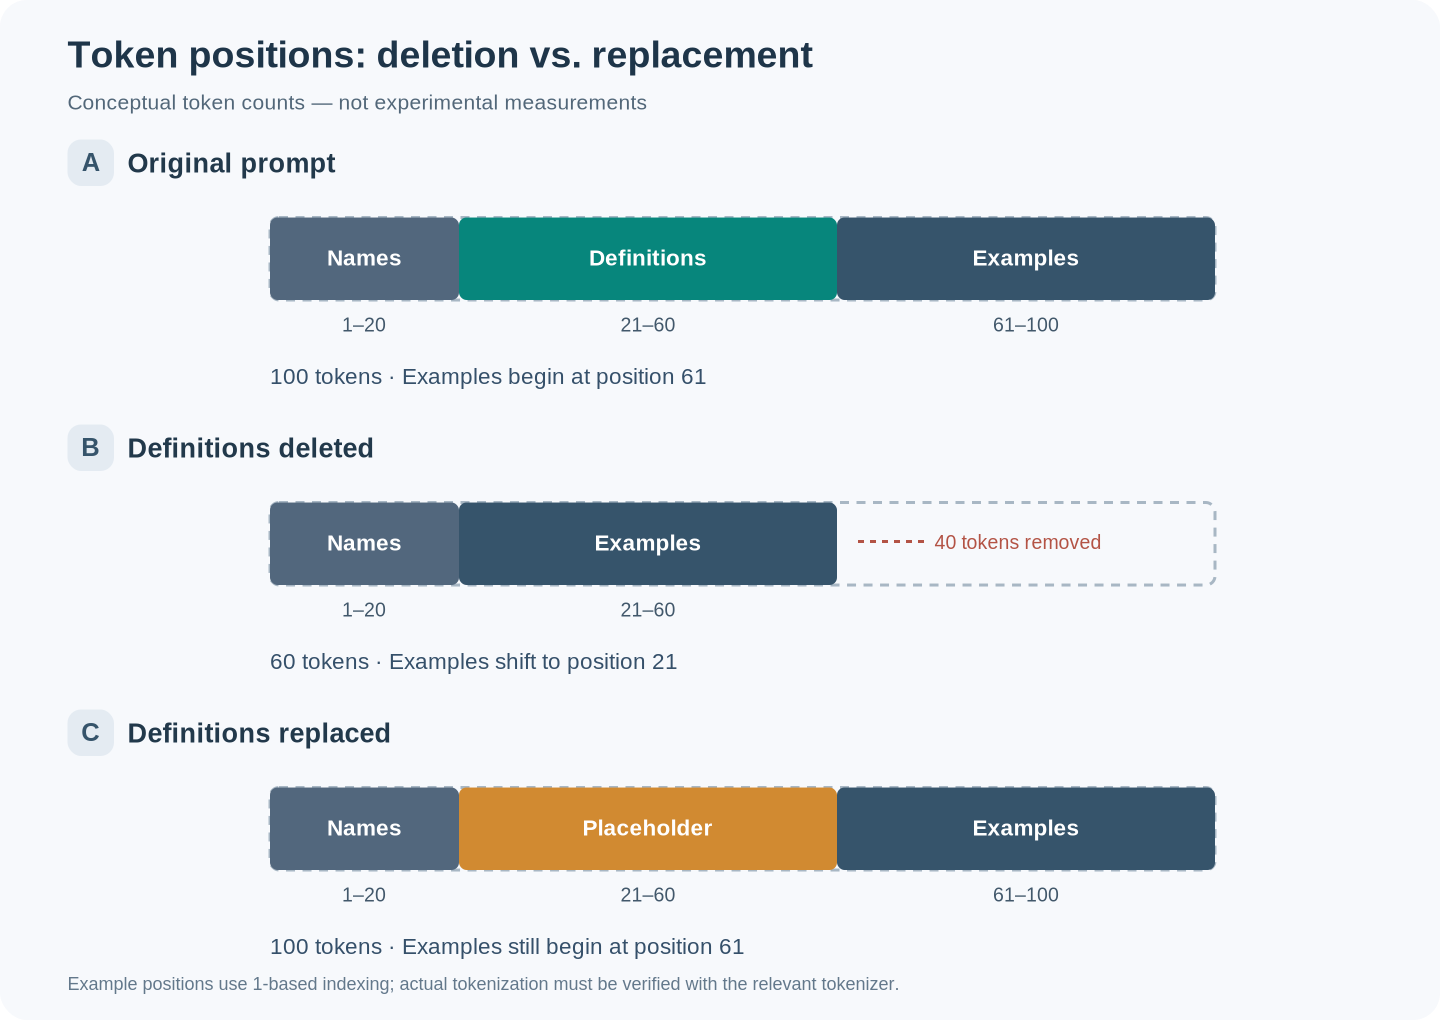

In [2]:
# The notebook generates the SVG locally; no LLM API is used.
display(SVG(token_position_svg()))

## 2. Why does deletion introduce a confound?

In the illustration, **Definitions** occupy 40 tokens.

| Feature | Original | Delete Definitions | Replace Definitions |
|---|---:|---:|---:|
| Total tokens | 100 | 60 | 100 |
| Names positions | 1–20 | 1–20 | 1–20 |
| Middle positions | Definitions: 21–60 | Absent | Placeholder: 21–60 |
| Examples positions | 61–100 | **21–60** | **61–100** |

Deleting Definitions changes **three things at once**: its content disappears, the prompt becomes shorter, and Examples move to earlier positions.

Replacing Definitions with the same number of placeholder tokens still changes the middle-block content, but it keeps the length and positions of the retained blocks the same **within the researcher-controlled prompt text**.

This is why replacement helps control *input-length* and *retained-content-position* differences in the comparison.

## 3. How this relates to my actual study

My independent study used **TalkMoves** classroom dialogue and a sample of **300 teacher utterances**. I compared a full-manual baseline with separate replacement conditions for **definitions**, **examples**, and **exclusion rules**, as well as a negative control and a names-only descriptive reference.

For the replacement conditions, I used placeholders made of `%` symbols separated by spaces. Each designated replacement instance was matched locally to the original component's token count, and token counts were verified for the experimental inputs. The aim was to keep the remaining manual text at the same positions without giving the model the selected manual content.

**The three-block illustration above is not the actual prompt architecture.** Actual prompts contained more structure, including the target utterance and surrounding dialogue; the toy numbers do not represent actual input lengths. The names-only reference was not token-matched to the full-manual conditions.

## 4. What the design does—and does not—control

**Controlled in the researcher-managed prompt text:**

- Total token length for the designated replacement inputs.
- Positions of retained content after the locally matched replacement sites.
- The same target utterance and contextual dialogue across conditions.

**Not isolated by the design:**

- Possible behavioral effects of the placeholder symbols themselves.
- Information about a replaced component that remained elsewhere in the manual.
- The provider's full internal request serialization or hidden token sequence.

Therefore, the findings describe **sensitivity to the implemented replacement procedures**. They do **not** demonstrate the independent contribution of each manual component, nor prove that placeholders are neutral.

## 5. Interview-ready summary

> If I simply deleted a component, the remaining text would shift to earlier token positions. So I replaced it with a placeholder of the same token length to keep the prompt length and the positions of the remaining content unchanged.

**Key takeaway:** *Deleting changes both information and structure. Token-matched replacement preserves the positions of retained content while changing the selected component.*

---

**Notebook scope:** This is an educational visualization of a design choice, not a replication of the experiment or a tokenizer audit. It loads no study data, runs no model calls, and reports no invented empirical results.